# MLForecast

`MLForecastAdapter` wraps a global ML model (one model fit across
the whole panel) with lags and calendar features doing the work that a
per-series statistical model does structurally.

We can then calibrate on the errors from the fitted ML model.

In [ ]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mlforecast import MLForecast
from mlforecast.target_transforms import Differences, LocalStandardScaler

from conformalforecast import (
    AdaptiveConformalInference,
    ConformalizedQuantileRegression,
    SplitConformal,
    SupportsCrossValidation,
    SupportsQuantiles,
    SupportsRefit,
    UnsupportedCapability,
)
from conformalforecast import (
    panel as P,
)
from conformalforecast.adapters import MLForecastAdapter
from conformalforecast.diagnostics import coverage_by_series, evaluate

HORIZON, SEASON, ALPHA = 24, 24, 0.1
N_HOLDOUT = 4

df = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
matrix, index = P.long_to_panel(df["y"].to_numpy(), df["unique_id"].to_numpy(), df["ds"].to_numpy())
print("panel", matrix.shape)

# Hold the tail out before anything is fitted, so the coverage measured at the
# end of this page is measured on data no part of the pipeline has seen.
train_df = df[df["ds"] <= df["ds"].max() - pd.Timedelta(hours=N_HOLDOUT * HORIZON)].reset_index(
    drop=True
)
print("training through", train_df["ds"].max(), f"({N_HOLDOUT * HORIZON} hours held out)")

panel (8, 672)
training through 2015-01-24 23:00:00 (96 hours held out)


## Fit the global model

Standard mlforecast: lags at the seasonal boundaries, calendar features, and two
target transforms: a per-series standard scaler and one seasonal differencing
step.

::: {.callout-warning}
## Scale the panel, or the small series get no interval at all

`LocalStandardScaler` is not decoration here. These eight series span three
orders of magnitude, and a single global tree model trained on unscaled targets
simply ignores the small ones — its splits are chosen to reduce error on `H50`,
whose values are in the tens of thousands. Dropping the scaler from this pipeline
takes marginal coverage from 95% to 71%, and the two smallest series (`H200`,
`H300`) from 96% and 83% down to **2% and 0%**.

Conformal prediction cannot repair that. Calibration widens a band around a point
forecast; it cannot make a forecast that ignores your series informative. Fix the
model first, then calibrate it.
:::

In [ ]:
mlf = MLForecast(
    models={
        "LGBMRegressor": lgb.LGBMRegressor(
            n_estimators=100, num_leaves=15, verbosity=-1, random_state=0, n_jobs=1
        )
    },
    freq="h",
    lags=[1, 2, 24, 48, 168],
    date_features=["hour", "dayofweek"],
    target_transforms=[LocalStandardScaler(), Differences([24])],
)
mlf.fit(train_df, static_features=[])

forecaster = MLForecastAdapter(
    mlf=mlf, train_df=train_df, horizon=HORIZON, freq="h", model_name="LGBMRegressor"
)

for capability in (SupportsRefit, SupportsCrossValidation, SupportsQuantiles):
    print(f"{capability.__name__:28s} {forecaster.supports(capability)}")

SupportsRefit                True
SupportsCrossValidation      True
SupportsQuantiles            False


## The one capability it lacks

`MLForecastAdapter` is a **point forecaster only**. There is no
`SupportsQuantiles`, so [CQR](../methods/cqr.html) is unavailable.

In [ ]:
# Construction only carries config, so it always succeeds. The gate fires
# where the forecaster is bound -- before any forecasting happens.
try:
    ConformalizedQuantileRegression(alpha=ALPHA).calibrate_cv(forecaster, n_windows=30)
except UnsupportedCapability as error:
    print(type(error).__name__)
    print(error)

UnsupportedCapability
ConformalizedQuantileRegression requires an adapter implementing SupportsQuantiles. Got MLForecastAdapter.


::: {.callout-note}
## Why not just ask LightGBM for quantiles?

Setting `objective="quantile"` fits one model per quantile, so you would need a
different `MLForecast` object per level, and the adapter speaks for one model.
The package does not paper over that with an abstraction that fits models behind
your back. If you want interval *shape* from a boosted model, the supported route
is [SPCI](../methods/spci.html), which learns the residual distribution instead.
:::

Everything else works. `MLForecastAdapter` also rejects a few configurations at
construction rather than later: an `MLForecast` built with mlforecast's own
`prediction_intervals=`, with static features, or with a weight column is refused
outright, because the adapter cannot honour those semantics.

## Calibrate and predict

In [ ]:
split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=30)
print("effective windows:", split.n_calibration_samples_)

aci = AdaptiveConformalInference(alpha=ALPHA, gamma=0.005).calibrate_cv(forecaster, n_windows=30)

prediction = split.predict(matrix)
print("interval", prediction.interval.shape)

effective windows: [30 30 30 30 30 30 30 30]


interval (8, 1, 24, 2)


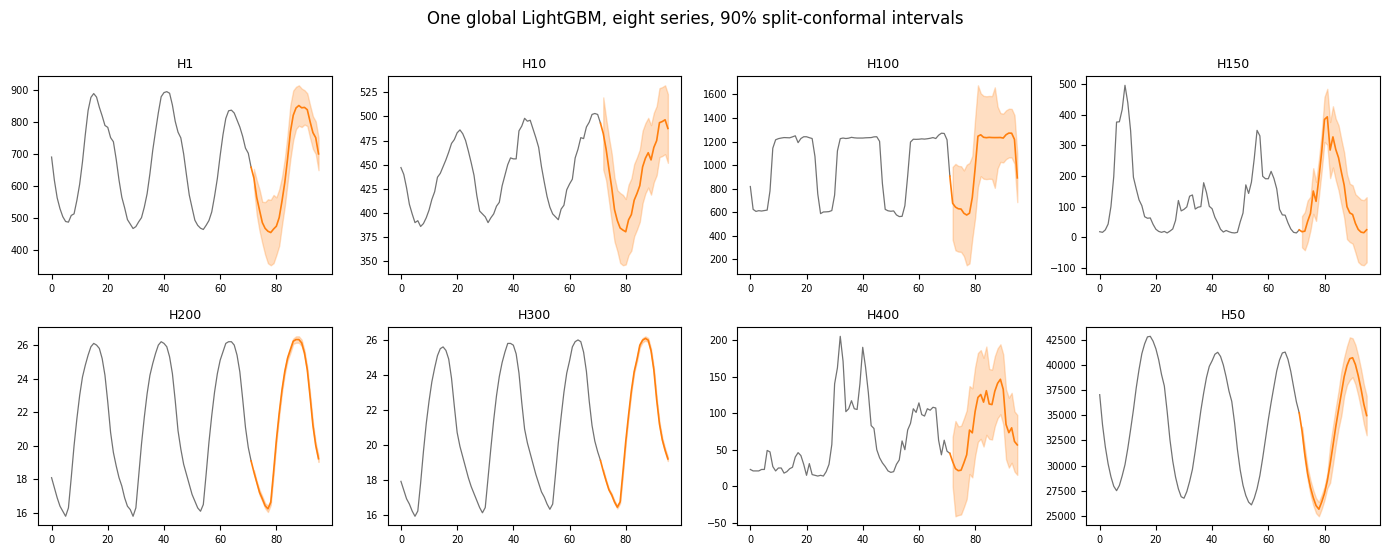

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
context = 72

for s, ax in enumerate(axes.ravel()):
    history = matrix[s]
    observed = history[~np.isnan(history)][-context:]
    past = np.arange(len(observed))
    future = np.arange(len(observed), len(observed) + HORIZON)
    join = np.r_[past[-1], future]

    ax.plot(past, observed, color="0.45", lw=0.9)
    ax.plot(join, np.r_[observed[-1], prediction.point[s, 0]], color="C1", lw=1.2)
    ax.fill_between(
        future,
        prediction.interval[s, 0, :, 0],
        prediction.interval[s, 0, :, 1],
        color="C1",
        alpha=0.25,
    )
    ax.set_title(index.series_ids[s], fontsize=9)
    ax.tick_params(labelsize=7)

fig.suptitle("One global LightGBM, eight series, 90% split-conformal intervals", y=1.0)
fig.tight_layout()

## Measured coverage

In [ ]:
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = matrix.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(matrix[:, :end])
    truths.append(matrix[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

reports = {
    name: evaluate(candidate, histories, truths)
    for name, candidate in [("LightGBM + Split", split), ("LightGBM + ACI", aci)]
}
for name, report in reports.items():
    print(
        f"{name:20s} coverage {report.marginal_coverage:6.1%}   "
        f"width {report.mean_interval_width:9.1f}   "
        f"Winkler {report.mean_winkler_score:9.1f}"
    )

split_report = reports["LightGBM + Split"]
per_series = coverage_by_series(split_report.intervals, split_report.truths)
print("\ncoverage per series:")
for name, value in zip(index.series_ids, per_series, strict=True):
    print(f"  {name:6s} {value:6.1%}")

LightGBM + Split     coverage  76.7%   width     496.0   Winkler    2225.3
LightGBM + ACI       coverage  77.6%   width     532.9   Winkler    2080.4

coverage per series:
  H1      78.1%
  H10     88.5%
  H100    91.7%
  H150    84.4%
  H200    97.9%
  H300    52.1%
  H400    70.8%
  H50     50.0%


Coverage lands at 76.7% against a 90% target, with `H300` and `H50` at barely
half. Nothing about the calibration is wrong: the interval is sized from
cross-validation windows inside the training period, and this holdout sits
entirely after it. A global tree model's error grows once the forecast origin
moves past where it was fitted, and a band calibrated before that point cannot
anticipate it — no conformal method can see, from inside the training data, that
the forecaster is about to get worse. Refitting on a schedule is the structural
answer. [ACI](../methods/aci.html) recovers a little of it (77.6%, and the better
Winkler score of the two) because `evaluate` feeds it the truths as it rolls,
but it is correcting a level when the problem is the point forecast.

::: {.callout-important}
## A global model does not give you global calibration

One LightGBM produced every forecast above, but the conformal quantile is still
taken per `(series, horizon)` cell. That is deliberate: a global model's errors
are systematically different across a panel whose series span three orders of
magnitude, and pooling residuals across them would give every series the same
band — far too wide for the small series, too narrow for the large ones.

Sharing the *model* across series and sharing the *calibration* across series are
independent choices, and this package makes the second one for you.
:::

## Next

- [StatsForecast](./statsforecast.html) — the same panel, per-series statistical models.
- [NeuralForecast](./neuralforecast.html) — and a neural global model.
- [SPCI](../methods/spci.html) — varying interval width without a quantile model.